# 05 · Sector exposure table (M8)

**What it shows.** For each sector group: its share of Canada's exports, its US dependence (exports to the US ÷ the sector's exports) in the baseline and in the latest 12 months, the change in percentage points, the concentration of its destinations (HHI) and how much of it is under a US tariff measure.

This table is descriptive; there is no hypothesis test. All numbers come from `mart_exposure`.

**HHI** (Herfindahl–Hirschman index) = the sum of squared destination shares. It is 1 when a sector sells to one country only and close to 0 when sales are spread over many countries.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, display

from src import analysis
from src.common import load_settings

pd.set_option("display.float_format", "{:,.3f}".format)
pd.set_option("display.max_colwidth", 60)
con = analysis.connect()
start, end = analysis.tariff_window(con)
print(f"Tariff period (latest 12 months): {start} to {end}")

Tariff period (latest 12 months): Oct 2025 to Sep 2026


## Exposure table, ordered by US dependence (latest 12 months)

In [2]:
def table(baseline):
    rows = analysis.exposure(con, baseline)
    return pd.DataFrame([{
        "sector": r["sector_group"], "tariffed sector": r["is_tariffed_sector"],
        "exports, latest (CAD bn)": r["x_sector_latest"] / 1e9,
        "share of exports, latest (%)": 100 * r["share_of_exports_latest"],
        "US dependence, baseline (%)": 100 * r["us_dependence_base"],
        "US dependence, latest (%)": 100 * r["us_dependence_latest"],
        "change (pp)": r["us_dependence_change_pp"],
        "HHI, baseline": r["hhi_base"], "HHI, latest": r["hhi_latest"],
        "full scope (%)": 100 * r["share_full_scope"], "partial scope (%)": 100 * r["share_partial_scope"],
        "no scope (%)": 100 * r["share_no_scope"],
    } for r in rows])

print("Baseline 2022–2024")
display(table("primary"))
print("Baseline 2023–2024")
display(table("sensitivity"))

Baseline 2022–2024


,sector,tariffed sector,"exports, latest (CAD bn)","share of exports, latest (%)","US dependence, baseline (%)","US dependence, latest (%)",change (pp),"HHI, baseline","HHI, latest",full scope (%),partial scope (%),no scope (%)
0,autos,True,61.880,7.918,94.159,91.919,-2.239,0.887,0.846,0.000,100.000,0.000
1,steel,True,8.468,1.084,94.149,89.416,-4.733,0.887,0.801,60.231,39.534,0.235
2,energy,False,219.014,28.026,89.907,82.860,-7.047,0.810,0.693,0.000,11.706,88.294
3,lumber,True,12.562,1.607,84.109,78.699,-5.411,0.713,0.627,99.618,0.382,0.000
4,aluminum,True,15.004,1.920,94.505,78.059,-16.446,0.894,0.628,92.827,7.119,0.053
5,other,False,390.891,50.020,66.817,65.723,-1.094,0.454,0.439,17.815,16.221,65.964
6,copper,True,1.369,0.175,97.058,39.671,-57.387,0.942,0.237,0.000,100.000,0.000
7,gold,False,72.276,9.249,22.454,6.329,-16.125,0.353,0.757,0.000,0.000,100.000


Baseline 2023–2024


,sector,tariffed sector,"exports, latest (CAD bn)","share of exports, latest (%)","US dependence, baseline (%)","US dependence, latest (%)",change (pp),"HHI, baseline","HHI, latest",full scope (%),partial scope (%),no scope (%)
0,autos,True,61.880,7.918,94.523,91.919,-2.603,0.894,0.846,0.000,100.000,0.000
1,steel,True,8.468,1.084,94.094,89.416,-4.678,0.886,0.801,60.231,39.534,0.235
2,energy,False,219.014,28.026,89.508,82.860,-6.648,0.803,0.693,0.000,11.706,88.294
3,lumber,True,12.562,1.607,83.557,78.699,-4.858,0.704,0.627,99.618,0.382,0.000
4,aluminum,True,15.004,1.920,93.886,78.059,-15.827,0.883,0.628,92.827,7.119,0.053
5,other,False,390.891,50.020,67.758,65.723,-2.034,0.466,0.439,17.815,16.221,65.964
6,copper,True,1.369,0.175,96.892,39.671,-57.221,0.939,0.237,0.000,100.000,0.000
7,gold,False,72.276,9.249,26.968,6.329,-20.639,0.322,0.757,0.000,0.000,100.000


**Tariff scope** columns give the share of the sector's latest-12-month exports by the scope of US sector-specific measures in the latest month: full (the whole product is covered), partial (only some tariff lines or part of the value, for example USMCA content), none.

## Chart

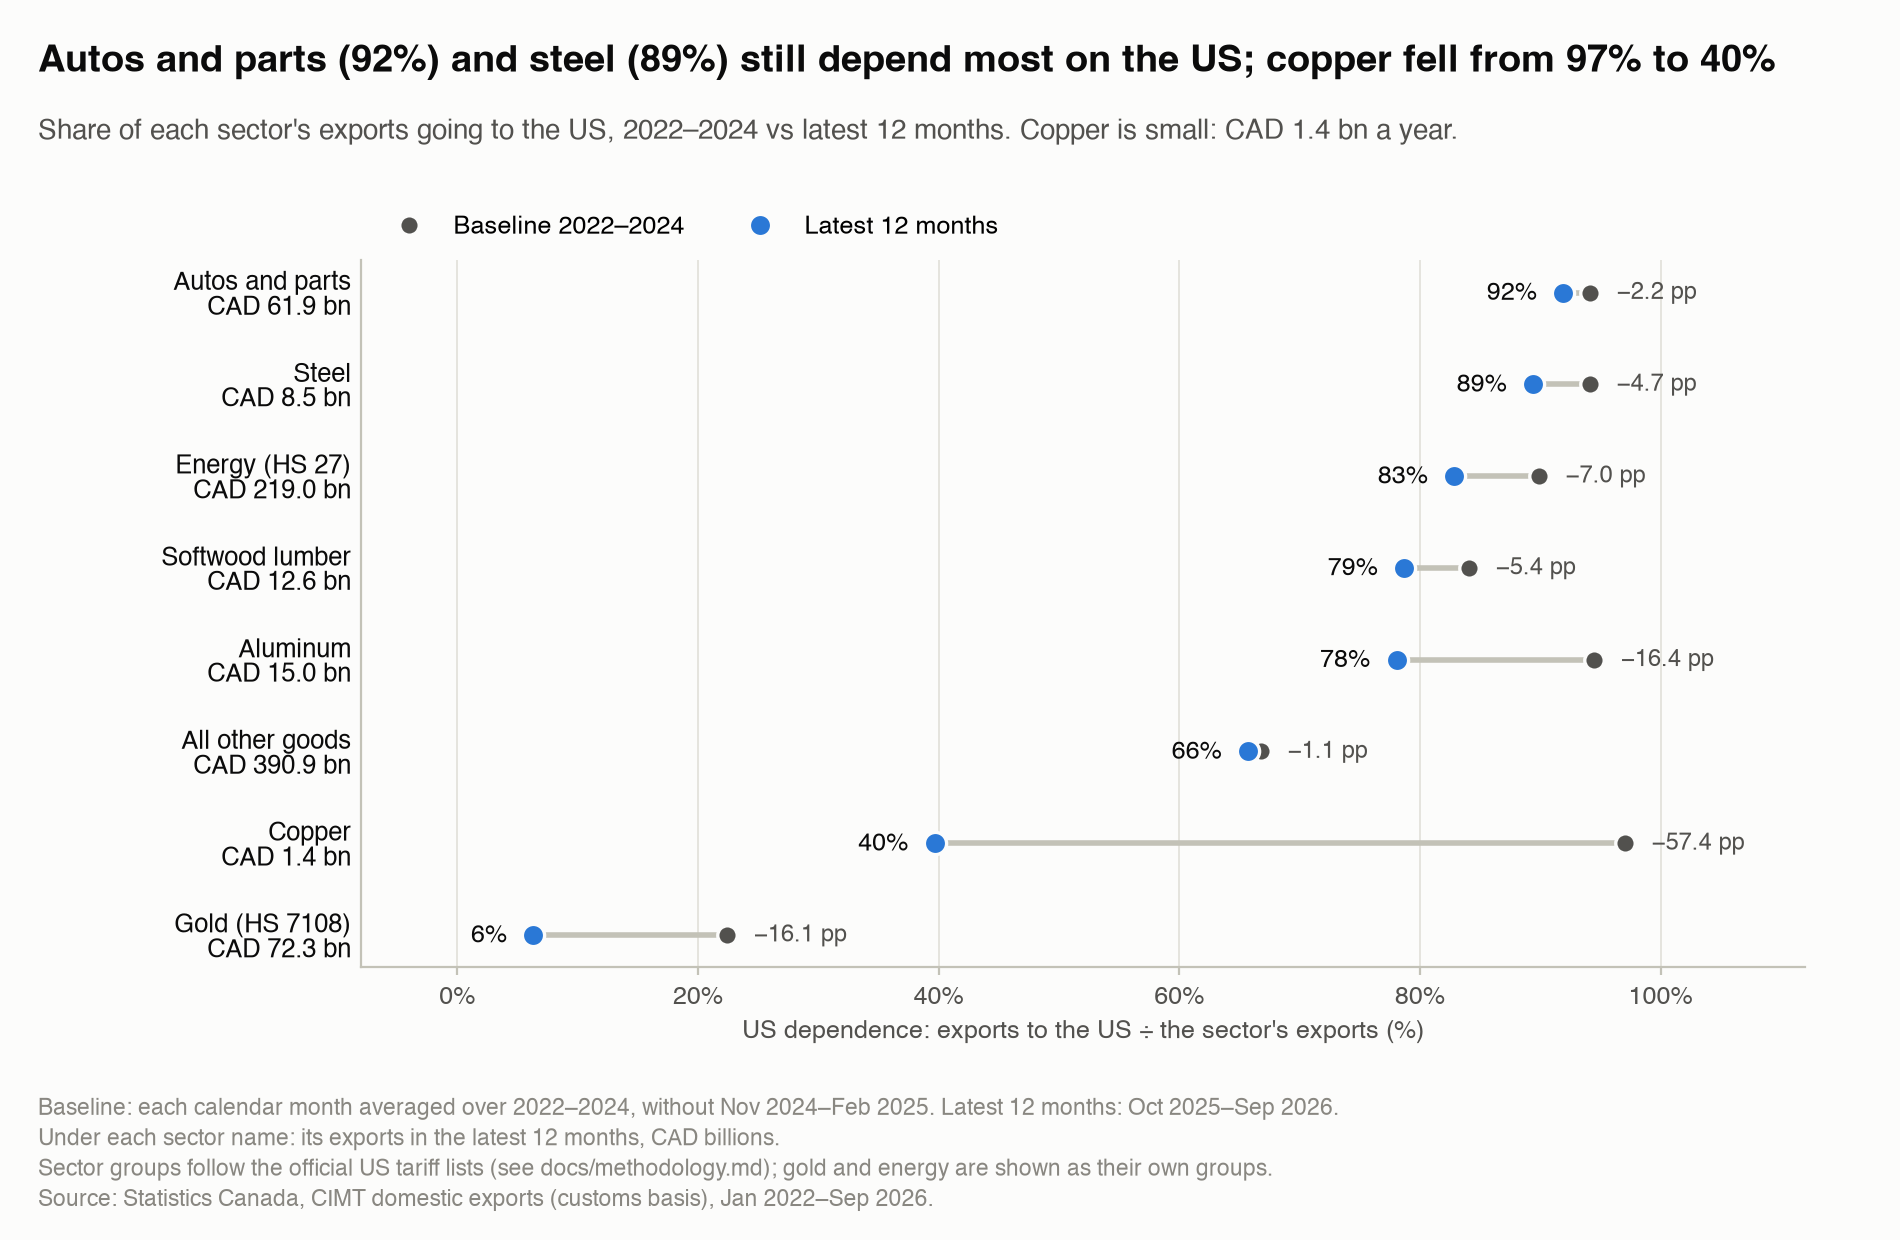

In [3]:
display(Image(filename=str(ROOT / "figures" / "m8_exposure.png"), width=900))

## Notes

- Sector groups follow the official US tariff lists. Gold (HS 7108) and energy (HS 27) are shown as their own groups; "other" is everything else.
- This is a description of the data. It does not show that tariffs caused the changes.